In [65]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

torch.manual_seed(42)
np.random.seed(42)


In [66]:
digits = load_digits()
X, y = digits.data, digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [67]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: torch.Size([1437, 64])
Testing data: torch.Size([360, 64])


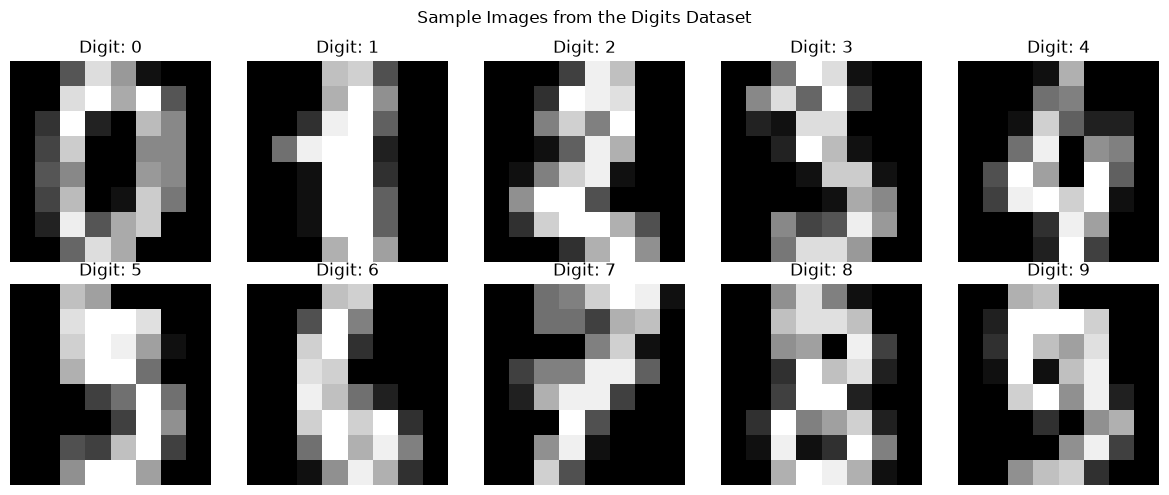

In [68]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for digit, ax in enumerate(axes.flat):
    index = np.where(digits.target == digit)[0][0]

    ax.imshow(digits.images[index], cmap="gray")
    ax.set_title(f"Digit: {digit}")
    ax.axis("off")

plt.suptitle("Sample Images from the Digits Dataset")
plt.tight_layout()
plt.show()

In [69]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)

In [70]:
model = MLP()

print(model)

print("Trainable parameters:",sum(p.numel() for p in model.parameters() if p.requires_grad))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

MLP(
  (network): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)
Trainable parameters: 17226


Epoch 10/50 | Loss: 0.0476
Epoch 20/50 | Loss: 0.0088
Epoch 30/50 | Loss: 0.0032
Epoch 40/50 | Loss: 0.0016
Epoch 50/50 | Loss: 0.0010


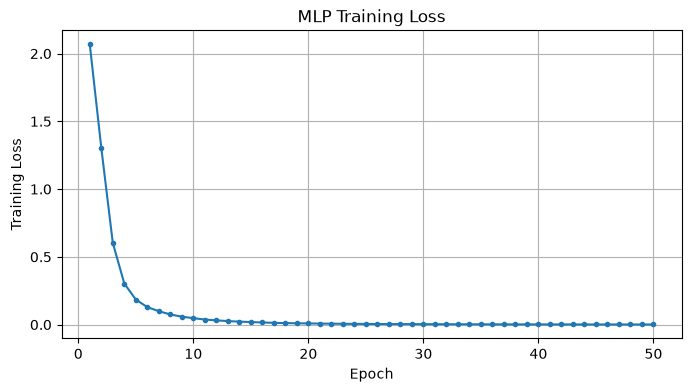

In [71]:
epochs = 50
batch_size = 64
loss_history = []

for epoch in range(epochs):
    model.train()
    permutation = torch.randperm(len(X_train))
    total_loss = 0.0

    for indices in permutation.split(batch_size):
        X_batch = X_train[indices]
        y_batch = y_train[indices]

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(indices)

    epoch_loss = total_loss / len(X_train)
    loss_history.append(epoch_loss)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss: {epoch_loss:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), loss_history, marker=".")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("MLP Training Loss")
plt.grid(True)
plt.show()

Test Accuracy: 97.50%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.94      0.97        36
           1       0.92      0.94      0.93        36
           2       0.95      1.00      0.97        35
           3       1.00      1.00      1.00        37
           4       0.95      1.00      0.97        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       1.00      1.00      1.00        36
           8       0.94      0.89      0.91        35
           9       1.00      0.97      0.99        36

    accuracy                           0.97       360
   macro avg       0.98      0.97      0.97       360
weighted avg       0.98      0.97      0.97       360



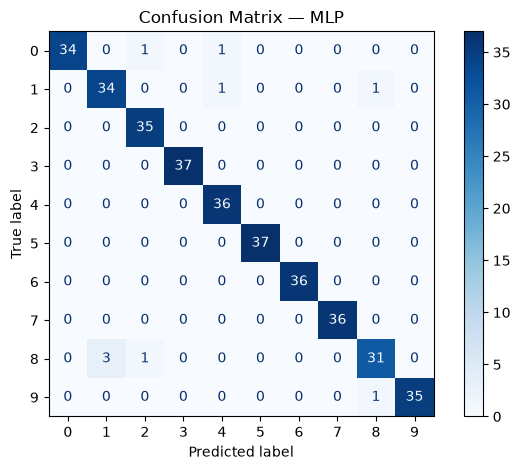

In [72]:
model.eval()

with torch.no_grad():
    test_logits = model(X_test)
    predictions = test_logits.argmax(dim=1)

accuracy = accuracy_score(y_test.numpy(), predictions.numpy())

print(f"Test Accuracy: {accuracy:.2%}")
print("\nClassification Report:")
print(classification_report(
    y_test.numpy(),
    predictions.numpy(),
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test.numpy(),
    predictions.numpy(),
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix — MLP")
plt.tight_layout()
plt.show()

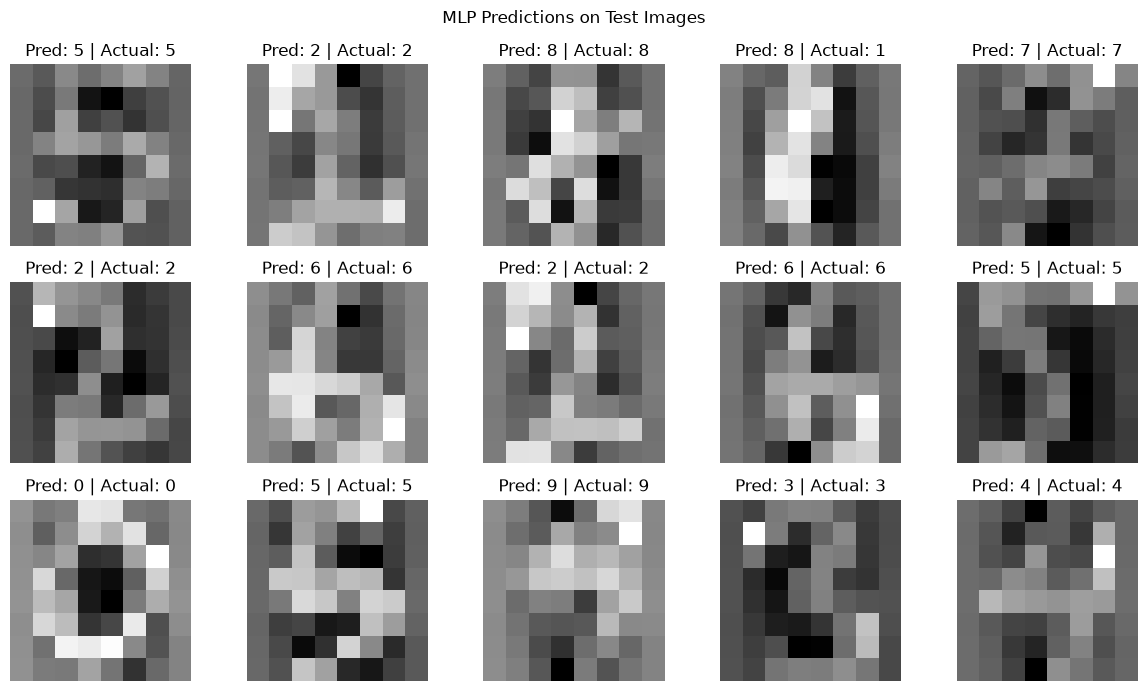

In [73]:
fig, axes = plt.subplots(3, 5, figsize=(12, 7))

for i, ax in enumerate(axes.flat):
    image = X_test[i].numpy().reshape(8, 8)

    actual = y_test[i].item()
    predicted = predictions[i].item()

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Pred: {predicted} | Actual: {actual}")
    ax.axis("off")

plt.suptitle("MLP Predictions on Test Images")
plt.tight_layout()
plt.show()

Incorrect predictions: 9 out of 360


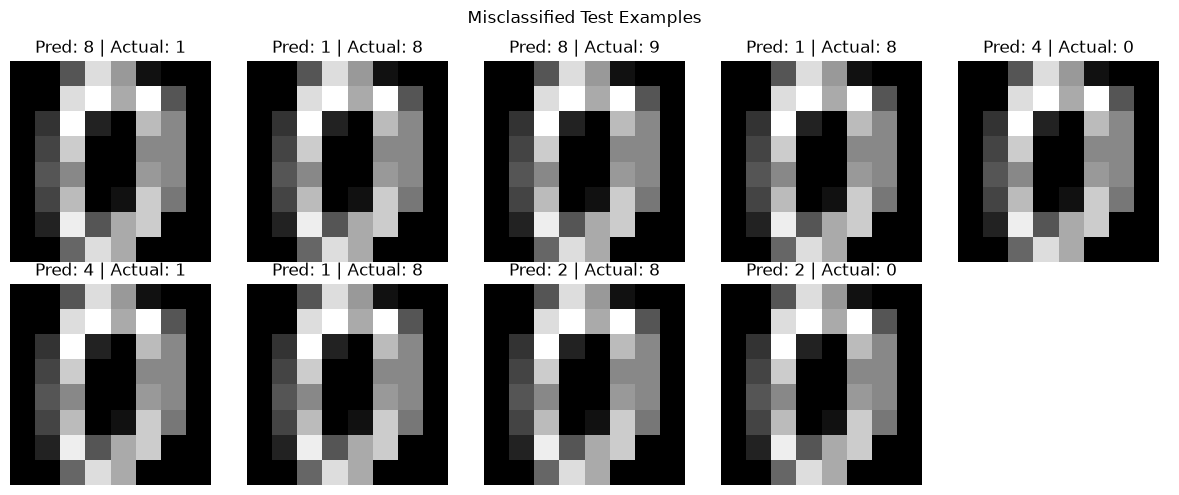

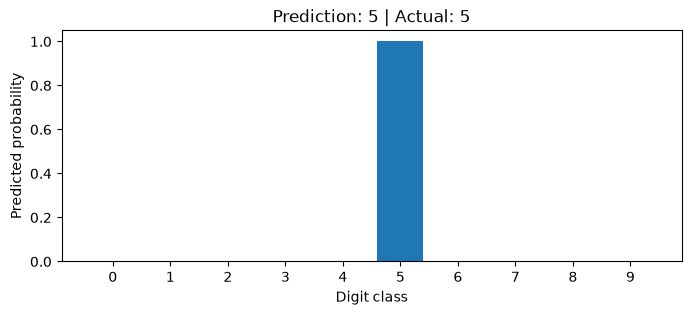

In [74]:
wrong = torch.where(predictions != y_test)[0]

print("Incorrect predictions:", len(wrong), "out of", len(y_test))

if len(wrong) > 0:
    count = min(10, len(wrong))
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))

    for ax, idx in zip(axes.flat, wrong[:count]):
        ax.imshow(digits.images[0], cmap="gray")
        ax.set_title(
            f"Pred: {predictions[idx].item()} | "
            f"Actual: {y_test[idx].item()}"
        )
        ax.axis("off")

    for ax in axes.flat[count:]:
        ax.axis("off")

    plt.suptitle("Misclassified Test Examples")
    plt.tight_layout()
    plt.show()

# Confidence for one test example
index = 0

with torch.no_grad():
    probabilities = torch.softmax(test_logits[index], dim=0)

plt.figure(figsize=(8, 3))
plt.bar(range(10), probabilities.numpy())
plt.xticks(range(10))
plt.xlabel("Digit class")
plt.ylabel("Predicted probability")
plt.title(
    f"Prediction: {predictions[index].item()} | "
    f"Actual: {y_test[index].item()}"
)
plt.show()

In [75]:
ax.imshow(
    X_test[idx].numpy().reshape(8, 8),
    cmap="gray"
)